# Visualizing fire scars through false color imaging

**Authors:**
- Olivia Knapp
- Carmen Galaz García (Instructor)

**GitHub Link:**
https://github.com/gingersknapp/eds220-hwk4

## Purpose
This notebook processes shapefiles of burn perimeters and satellite-based remote-sensing data to visualize the one-month post-fire burnscars from the 2025 Eaton and Palisades Fire using true color and false color imaging.

## Highlights
- Geospatial data wrangling with `geopandas`
- NetCDF raster data wrangling with `xarray` and `rioxarray`
- True and False color imaging with `matplotlib` and `xarray`

## About the data

Shapefiles for the Eaton and Palisades Fire perimeters were downloaded from the [County of LA](https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about) based on [CAL FIRE's Historical Fire Perimeter Dataset](https://www.arcgis.com/home/item.html?id=c3c10388e3b24cec8a954ba10458039d#overview). Daily perimeters were dissolved into one total perimeter for each fire summarizing the entire fire duration. They are processed as shapefiles.

Satellite-based remote-sensing data from LANDSAT 8 was obtained through the [Microsoft Planetary Computer data catalog](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2). It is processed as a raster.

## References

County of Los Angeles. (2025). Palisades and Eaton Dissolved Fire Perimeters (2025). County of Los Angeles Open Data. https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about  

Earth Resources Observation and Science (EROS) Center. (2020). Landsat 8-9 Operational Land Imager / Thermal Infrared Sensor Level-2, Collection 2 [dataset]. U.S. Geological Survey. https://doi.org/10.5066/P9OGBGM6.  It contains reflectance values of a given area in five wavelength bands (red, green, blue, near infrared, and shortwave infrared) captured at a resolution of 30 meters by Landsat 8's Operational Land Imager (OLI) and Thermal Infrared Sensor (TIRS)

Riebeek, H. (2025). Why is that Forest Red and that cloud blue? how to interpret a false-color satellite image - NASA science. NASA Earth Observatory. https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/ 

U.S. Geological Survey. (2026). What are the band designations for the Landsat Satellites?. USGS. https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites 


In [ ]:
# Import packages

import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import rioxarray as rioxar
import xarray as xr 


## Fire Perimeter Data Exploration

In [ ]:
# Import fire perimeter shapefiles
eaton = gpd.read_file(os.path.join('data', 
                                    'Eaton_Perimeter_20250121.shp'))
palisades = gpd.read_file(os.path.join('data', 
                                    'Palisades_Perimieter_20250121.shp'))

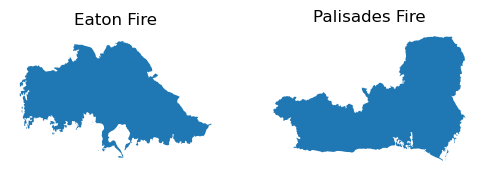

In [261]:
# View fire perimeters
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize=((6,3)))

eaton.plot(ax = axes[0])
axes[0].set_title('Eaton Fire')
axes[0].axis('off')

palisades.plot(ax = axes[1])
axes[1].set_title('Palisades Fire')
axes[1].axis('off')

plt.show();

In [262]:
# Check file size and CRS
print(f'Eaton: Number of polygons: {eaton.shape[0]}, CRS: {eaton.crs}')
print(f'Palisades: Number of polygons: {palisades.shape[0]}, CRS: {palisades.crs}')


Eaton: Number of polygons: 1, CRS: EPSG:4269
Palisades: Number of polygons: 1, CRS: EPSG:4269


Eaton and Palisade Fire Perimeters were obtained from [CAL FIRE's Historical Fire Perimeter Dataset](https://www.arcgis.com/home/item.html?id=c3c10388e3b24cec8a954ba10458039d#overview) through the [County of Los Angeles](https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about).  The county dissolved daily fire perimeters from the original dataset into a single burn perimeter.

Both shapefiles share the same CRS: EPSG: 4269.  It is a geographic (not projected) CRS. Each contain a single polygon of the fire perimeter

## NETCDF data import and exploration

In [308]:
# Import the landsat data
burnscar =xr.open_dataset("data\landsat8-2025-02-23-palisades-eaton.nc")
burnscar

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

In [306]:
# Identify date/time of collection
print('Time of collection: ', pd.to_datetime(burnscar.time.item()))

Time of collection:  2025-02-23 18:28:13.651369


The data from Landsat 8 contains 5 wavelength ranges as variables (`red`, `green`, `blue`, `nir08` (near infrared), and `swir22` (shortwave infrared)) in 3 dimensions (x,y, and time).  X and Y are coordinates in the corresponding projected axes, and the data only covers one time (February 23, 2025) Geospatial information is stored in the variable `spatial_ref`. Values are stored as floats.  The raster is 2742 cells wide and 1418 cells long, at a resolution of 30 meters.  It lies in the bounding box `(334395.0, 3756525.0, 416655.0, 3799065.0)`.  The CRS of the coordinates is EPSG: 32611, which is a projected CRS.

## Restoring geospatial information

In [ ]:
# Identify CRS of the landsat data
print('CRS: ', burnscar.rio.crs)

CRS:  None


`rio.crs` does not return a CRS, indicating that this is not a geospatial object.  CRS information is instead stored under `spatial_ref`

In [63]:
# Identify CRS through `spatial-ref`
print('CRS: ', burnscar.spatial_ref.crs_wkt)

CRS:  PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


We can restore the geospatial information by using `rio.write_crs` to assign the CRS stored in `spatial_ref`:

In [64]:
# Restore geospatial infomration
burnscar = burnscar.rio.write_crs(burnscar.spatial_ref.crs_wkt, inplace = True)

# Confirm restoration
print('CRS :', burnscar.rio.crs)

CRS : EPSG:32611


## True Color Image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


c:\Users\olivi\.conda\envs\eds220-env\Lib\site-packages\matplotlib\cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


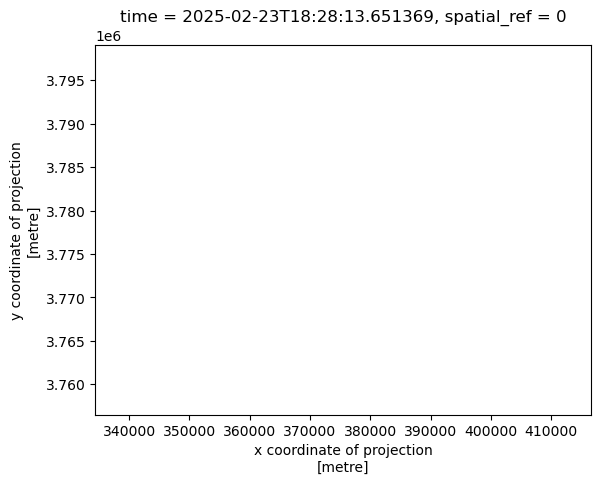

In [ ]:
# Plot a true color image
(burnscar[['red', 'green', 'blue']]
 .to_dataarray()
 .plot.imshow())

This attempt generated two errors:
1) Invalid range for RGB plotting, resulting in the blank image
- We can fix this by setting `plot.imshow(robust = True)`.
2) Missing values
- We can fix this by assigning missing values a value, but first we'll check how many values are missing and where.

c:\Users\olivi\.conda\envs\eds220-env\Lib\site-packages\matplotlib\cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


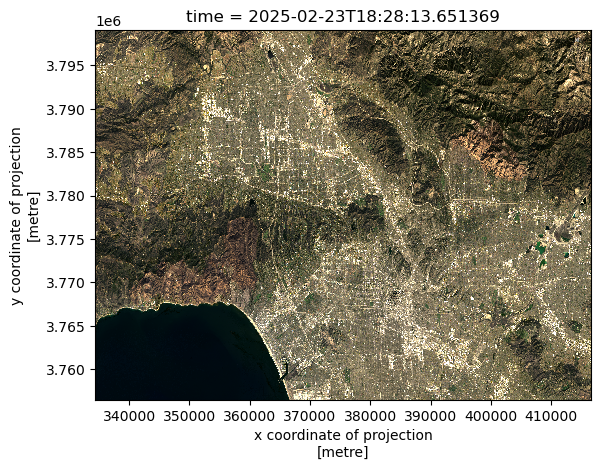

In [309]:
# Plot a true color image
(burnscar[['red', 'green', 'blue']]
 .to_dataarray()
 .plot.imshow(robust = True))

Now that we have corrected the color scaling using `robust = True`, we can consider the missing data.

In [276]:
# Count how many values are missing in each variable (wavelength band) 
burnscar.isnull().sum()

<xarray.Dataset> Size: 32B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int32 4B 0
Data variables:
    red          int32 4B 0
    green        int32 4B 1
    blue         int32 4B 109
    nir08        int32 4B 0
    swir22       int32 4B 0

In [274]:
# Identify total values in raster file per wavelength band
print('Total expected values per wavelength: ', burnscar.rio.shape[0] * burnscar.rio.shape[1])

Total expected values per wavelength:  3888156


Green and blue bands are missing values.  Green is missing just one value, but blue is missing 109.  We have a total of 3,888,156 for each band, so the absence of values likely will not affect our conclusions.  We can fill them with a replacement value of 0.

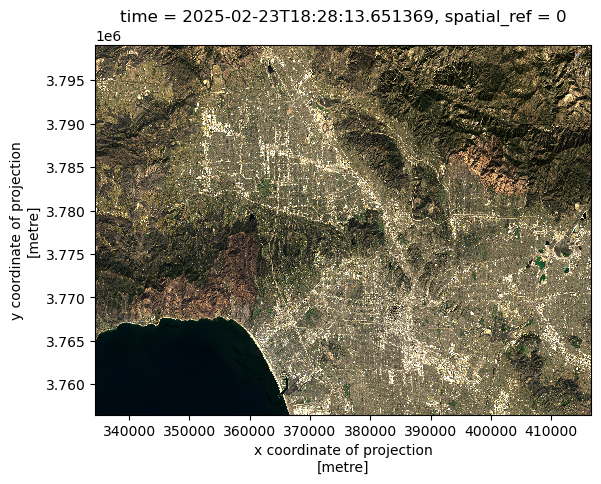

In [ ]:
# Plot a true color image
ax.axis('off')
(burnscar[['red', 'green', 'blue']]  # Select red, green, and blue bands
 .fillna(0)                           # Fill missing values with 0
 .to_dataarray()                      # Convert to dataArray                        
 .plot.imshow(robust= True));

### In Summary

The inital attempt did not plot as expected.  This is likely because there were outlier values that skewed the color scale for the plotting the bands, as `plot.imshow()` bases the scale on maximum and minimum values.  Setting `robust=True` causes`plot.imshow()` to instead use the 2nd and 98th percentile values to create a color scale, eliminating the effect of the outliers.  Plotting without correcting for missing values also generated a warning because both the green and blue bands were missing values, but not a significant portion.  Using `fillna(0)` set the missing values to 0.

## False color image

To create a false-color image, we assign non-visible wavelengths to colors that we can see.  Healthy vegetation reflects near infrared wavelengths, so we can assign near-infrared to the green color to highlight healthy vegetation.  Assigning shortwave infrared to red will highlight recently-burned areas since they reflect shortwave infrared light. None of these bands are missing values, so we do not need to fill missing data, but we will set `robust = True` to handle any outliers in the color scaling.

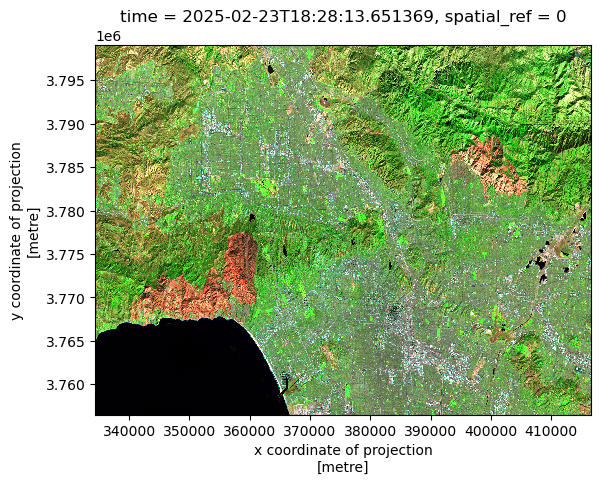

In [283]:
# Create a false color image

(burnscar[['swir22', 'nir08', 'red']]  # Select shortwave infrared, near-infrared, and red bands                          # Fill missing values with 0
 .to_dataarray()                     # Convert to dataArray                        
 .plot.imshow(robust= True))

## Map

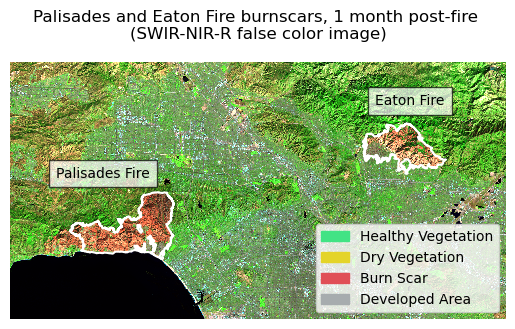

In [286]:
# Identify Eaton and Palisades Fire burnscars on false color map
from matplotlib.patches import Patch

map_aspect_ratio = burnscar.rio.width/burnscar.rio.height
figsize = (8*map_aspect_ratio, 8)
fig, ax = plt.subplots()

ax.axis('off')

# Plot a false color image
(burnscar[['swir22', 'nir08', 'red']]  # Select shortwave infrared, near-infrared, and red bands
 .fillna(0)                           # Fill missing values with 0
 .to_dataarray()                     # Convert to dataArray                        
 .plot.imshow(robust= True, ax = ax))

# Add Eaton Fire perimeter
eaton.to_crs(burnscar.rio.crs).plot(    
    ax = ax,   
    facecolor = 'none',               
    edgecolor = 'white',
    linewidth = 1.5,
    label = "Eaton Fire")  
  
 # Add Palisades Fire perimeter
palisades.to_crs(burnscar.rio.crs).plot(  
    ax = ax,
    facecolor = 'none',              
    edgecolor = 'white',
    linewidth =1.5,
    label = "Palisades Fire") 

color_scale = [Patch(facecolor="#42E385", edgecolor="#42E385",
                         label='Healthy Vegetation'),
               Patch(facecolor="#E4D429", edgecolor= "#E4D429",
                                        label='Dry Vegetation'),
               Patch(facecolor="#E04F57", edgecolor= "#E04F57",
                         label='Burn Scar'),
               Patch(facecolor="#A7ACAE", edgecolor="#A7ACAE",
                         label='Developed Area')]


ax.set_title("Palisades and Eaton Fire burnscars, 1 month post-fire \n(SWIR-NIR-R false color image)")
ax.legend(handles = color_scale, loc = 'lower right')
ax.text(395000, 3792000, "Eaton Fire", bbox ={'facecolor': 'white', 'alpha': 0.7, 'pad': 5})
ax.text(342000, 3780000, "Palisades Fire", bbox ={'facecolor': 'white', 'alpha': 0.7, 'pad': 5})
plt.show()


False color imaging reveals that clear burnscars are evident in the areas of the Palisades and Eaton fires one month post-burn.  Much of the surrounding area appears bright green due to high near-infrared reflectance, indicating the presence of healthy vegetation.  In contrast, the burn scars appear red, reflecting considerable light in the short-wave infrared spectrum, indicating exposed soil.  The majority of the area in the burnscars are in undeveloped areas (surrounded by vegetation), though the lower right corner of the Palisades burnscar and left side of the Eaton burnscar overlap with developed areas, suggesting an impact on infrastuture in those areas.